# Fig S11 (draft) · Lymph node 5k: the block structure at 100 to 1,600 genes

The layout rebuilt at the top 100, 200, 400, 800 and 1,600 variable genes (one column each). One example tile 1 (median
cell count, largest niche at 400 genes) and a partner, tile 2, that shares its niche at every gene count; every matrix
is in the gene order of tile 1's niche, with the niche's blocks outlined.

* **A** the niche's mean correlation matrix; below it the mean |r| inside and between blocks.
* **B** tile 1's correlation matrix (what one tile looks like).
* **C** |log C_1 − log C_2|, the entries whose squared sum is p·d_W²; below it the share of that sum outside the
  blocks (what d_B leaves out).
* **D** d_B against d_W for the 1,000 random same-niche pairs (Fig S10's test); dashed y = x.

Correlations, not covariances: covariance colours follow each gene's variance and hide the co-variation pattern.

**Run first:** `R13_block_distance_genes` (`results/block_distance_genes/scale_examples.npz`, `genes_pairs.csv`).
Writes `figures/figS11_block_distance_genes/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator
from scipy.stats import pearsonr, spearmanr

import style as ps

FIG = "figS11_block_distance_genes"
RES = ROOT / "results" / "block_distance_genes"
z = np.load(RES / "scale_examples.npz")
pairs = pd.read_csv(RES / "genes_pairs.csv")
GENES = [int(n) for n in z["genes"]]
M = {n: {k[len(f"p{n}_"):]: z[k] for k in z.files if k.startswith(f"p{n}_")} for n in GENES}

W, LEFT, RIGHT = 180.0, 7.0, 13.0          # mm: page, row-label strip, colour-bar strip
CW = (W - LEFT - RIGHT) / len(GENES)        # column width
SIDE = CW - 2.0                             # matrix side
TOP, NOTE = 6.0, 5.0                        # column titles above row A; note under each matrix
MH = SIDE + NOTE + 1.0                      # matrix row height
SH = 34.0                                   # scatter row height
CORR_MEAN, CORR_TILE = 0.3, 0.6             # colour limits (|r|)
DASH, DLW = (0, (3, 2)), 0.6
COLOR = ps.DATASET_COLORS["lymph_node_5k"]


def masks(n):
    p = len(M[n]["perm"]); within = np.zeros((p, p), bool)
    for s, e in M[n]["runs"]:
        within[s:e, s:e] = True
    off = ~np.eye(p, dtype=bool)
    return within & off, ~within


LOGMAX = float(np.percentile(M[400]["abs_log_diff"].astype(float)[masks(400)[1]], 99))
for n in GENES:
    w, b = masks(n); m = M[n]
    print(f"{n:5d} genes: niche {int(m['niche'])} ({int(m['niche_tiles'])} tiles, {len(m['runs'])} blocks); "
          f"mean |r| within {np.abs(m['mean_corr'][w].astype(float)).mean():.3f}, between {np.abs(m['mean_corr'][b].astype(float)).mean():.3f}")

  100 genes: niche 10 (285 tiles, 4 blocks); mean |r| within 0.079, between 0.040
  200 genes: niche 3 (728 tiles, 10 blocks); mean |r| within 0.077, between 0.048
  400 genes: niche 0 (873 tiles, 20 blocks); mean |r| within 0.071, between 0.041
  800 genes: niche 5 (618 tiles, 47 blocks); mean |r| within 0.054, between 0.031
 1600 genes: niche 3 (740 tiles, 96 blocks); mean |r| within 0.045, between 0.022


## Rows A–C: matrices

figures/figS11_block_distance_genes/panels/A.pdf/.png: 180 x 42 mm, 2.1 / 5.4 MB
figures/figS11_block_distance_genes/panels/B.pdf/.png: 180 x 36 mm, 2.7 / 8.6 MB
figures/figS11_block_distance_genes/panels/C.pdf/.png: 180 x 36 mm, 2.8 / 8.9 MB


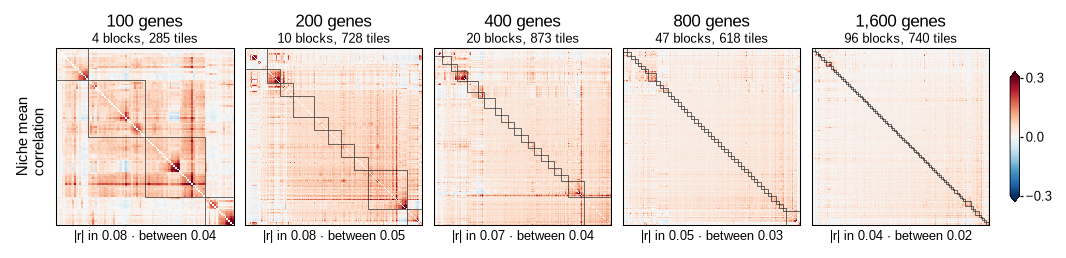

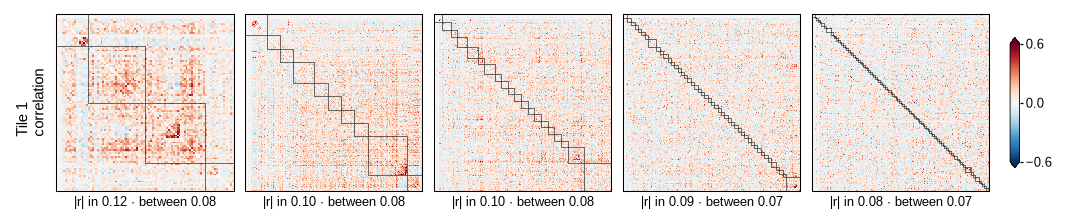

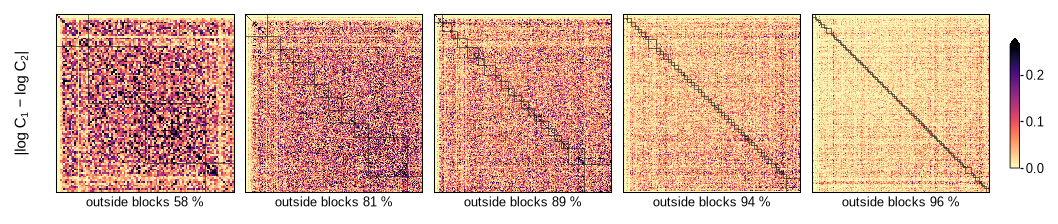

In [2]:
def blocks(ax, n):
    for s, e in M[n]["runs"]:
        ax.add_patch(Rectangle((s - 0.5, s - 0.5), e - s, e - s, fill=False, lw=0.3, ec=ps.INK))


def matrix_row(fig, what, titles=False):
    Wf, Hf = ps.size_mm(fig)
    y0 = TOP if titles else 0.0
    for i, n in enumerate(GENES):
        m = M[n]; w, b = masks(n)
        x = LEFT + i * CW + 1.0
        ax = fig.add_axes([x / Wf, 1 - (y0 + SIDE) / Hf, SIDE / Wf, SIDE / Hf])
        A = m[what].astype(np.float32)
        if what == "abs_log_diff":
            ax.imshow(A, cmap="magma_r", vmin=0, vmax=LOGMAX, interpolation="nearest")
            sq = A.astype(float) ** 2
            note = f"outside blocks {100 * sq[b].sum() / sq.sum():.0f} %"
        else:
            lim = CORR_MEAN if what == "mean_corr" else CORR_TILE
            ax.imshow(np.where(np.eye(len(A), dtype=bool), np.nan, A), cmap=ps.DIVERGING, vmin=-lim, vmax=lim,
                      interpolation="nearest")
            aw, ab = np.abs(A[w].astype(float)).mean(), np.abs(A[b].astype(float)).mean()
            note = f"|r| in {aw:.2f} · between {ab:.2f}"
        blocks(ax, n)
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(True); sp.set_linewidth(0.5)
        fig.text((x + SIDE / 2) / Wf, 1 - (y0 + SIDE + 0.8) / Hf, note, ha="center", va="top", fontsize=ps.TICK_PT - 1)
        if titles:
            fig.text((x + SIDE / 2) / Wf, 1 - 0.3 / Hf, f"{n:,} genes", ha="center", va="top", fontsize=ps.LABEL_PT)
            fig.text((x + SIDE / 2) / Wf, 1 - 3.4 / Hf, f"{len(m['runs'])} blocks, {int(m['niche_tiles'])} tiles",
                     ha="center", va="top", fontsize=ps.TICK_PT - 1)
    label = {"mean_corr": "Niche mean\ncorrelation", "tile_corr": "Tile 1\ncorrelation",
             "abs_log_diff": "|log C$_1$ − log C$_2$|"}[what]
    fig.text(1.0 / Wf, 1 - (y0 + SIDE / 2) / Hf, label, rotation=90, ha="left", va="center", fontsize=ps.TICK_PT)
    cax = fig.add_axes([(W - RIGHT + 2.5) / Wf, 1 - (y0 + SIDE - 4) / Hf, 1.6 / Wf, (SIDE - 8) / Hf])
    if what == "abs_log_diff":
        cb = fig.colorbar(ScalarMappable(Normalize(0, LOGMAX), "magma_r"), cax=cax, extend="max")
    else:
        lim = CORR_MEAN if what == "mean_corr" else CORR_TILE
        cb = fig.colorbar(ScalarMappable(Normalize(-lim, lim), ps.DIVERGING), cax=cax, extend="both")
        cb.set_ticks([-lim, 0, lim])
    cb.outline.set_linewidth(0.4); cb.ax.tick_params(labelsize=ps.TICK_PT - 1, length=1.5)


H_A = TOP + MH
for letter, what, h, t in (("A", "mean_corr", H_A, True), ("B", "tile_corr", MH, False), ("C", "abs_log_diff", MH, False)):
    fig = ps.panel(W, h); matrix_row(fig, what, titles=t); ps.save_panel(fig, FIG, letter)

## Row D: d_B against d_W

figures/figS11_block_distance_genes/panels/D.pdf/.png: 180 x 34 mm, 0.1 / 0.6 MB


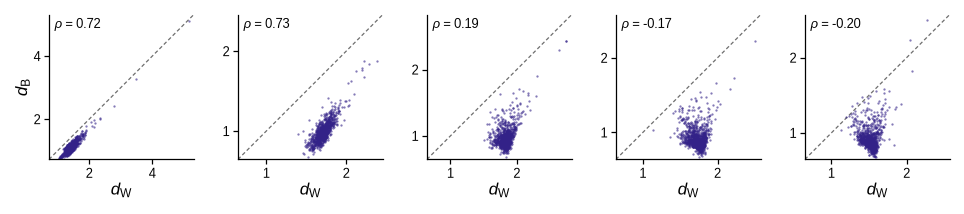

In [3]:
def scatter_row(fig):
    Wf, Hf = ps.size_mm(fig)
    for i, n in enumerate(GENES):
        g = pairs[pairs.n_genes == n]
        x = LEFT + i * CW
        a_w = CW - 7.5
        ax = fig.add_axes([(x + 6.5) / Wf, 1 - (2 + a_w) / Hf, a_w / Wf, a_w / Hf])
        lo = 0.95 * min(g.d_whole.min(), g.d_block.min()); hi = 1.03 * max(g.d_whole.max(), g.d_block.max())
        ax.plot([lo, hi], [lo, hi], color=ps.MUTED, lw=DLW, ls=DASH, zorder=1)
        ax.scatter(g.d_whole, g.d_block, s=1.2, lw=0, alpha=0.6, color=COLOR, zorder=2)
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
        for a in (ax.xaxis, ax.yaxis):
            a.set_major_locator(MaxNLocator(nbins=4, integer=True, steps=[1, 2, 5, 10]))
        ax.tick_params(labelsize=ps.TICK_PT - 1)
        ax.set_xlabel("$d_{\\mathrm{W}}$", labelpad=1)
        if i == 0:
            ax.set_ylabel("$d_{\\mathcal{B}}$", labelpad=1)
        ax.text(0.04, 0.97, f"$\\rho$ = {spearmanr(g.d_whole, g.d_block)[0]:.2f}", transform=ax.transAxes,
                va="top", ha="left", fontsize=ps.TICK_PT - 1)


fig = ps.panel(W, SH); scatter_row(fig); ps.save_panel(fig, FIG, "D")

## Full figure

figures/figS11_block_distance_genes/figS11_block_distance_genes.pdf/.png: 180 x 148 mm, 7.7 / 23.6 MB


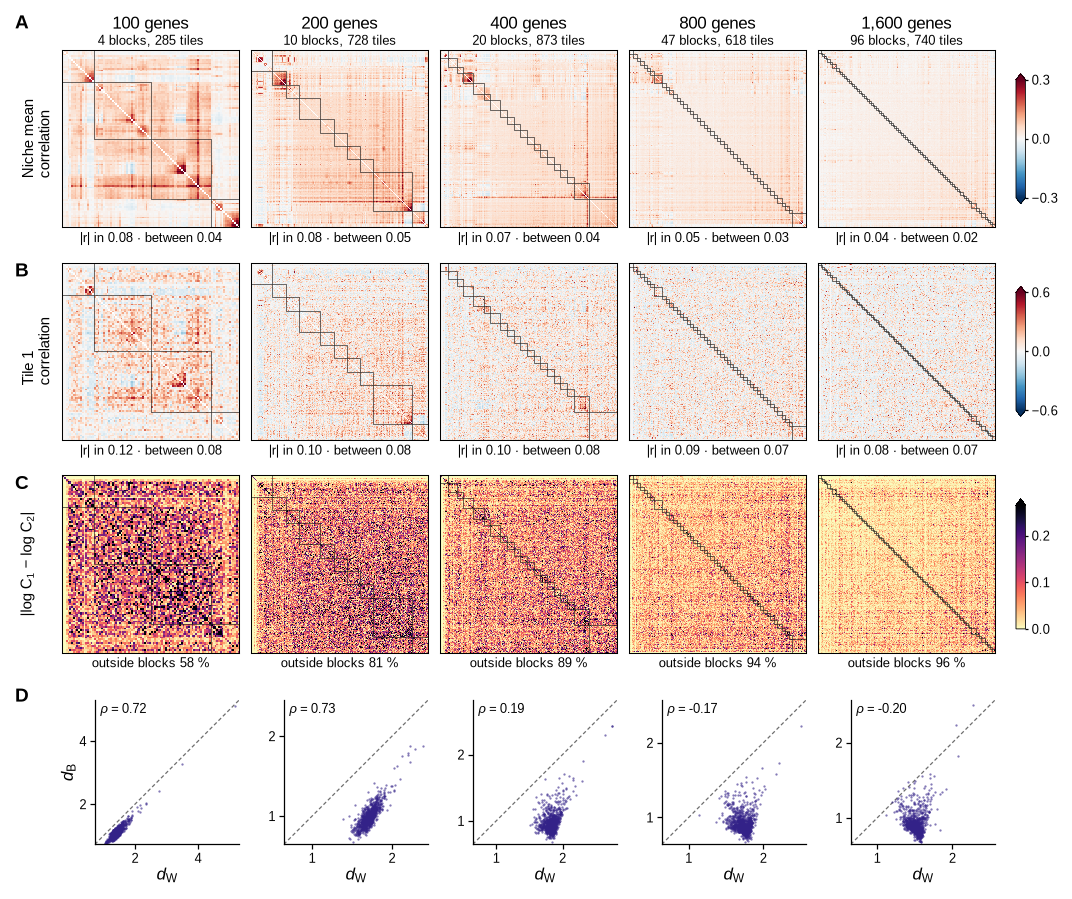

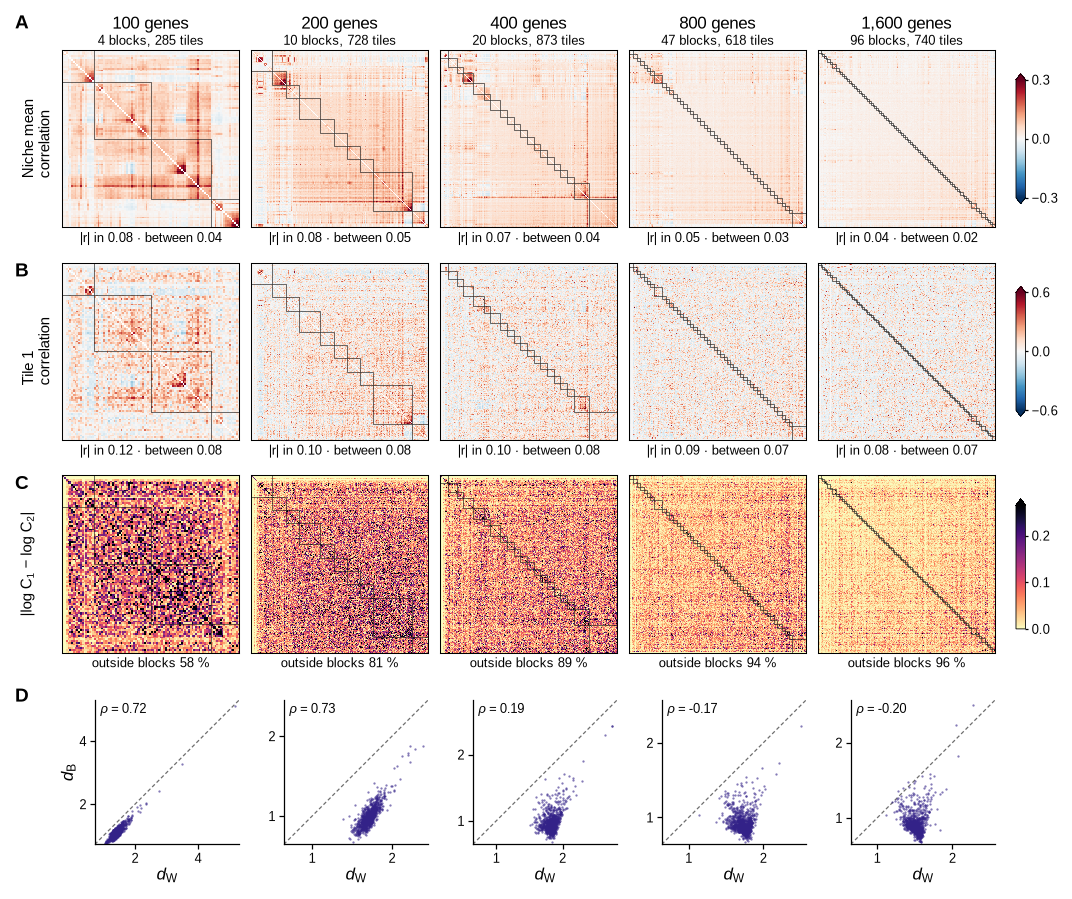

In [4]:
page = ps.page(W, H_A + 2 * MH + SH)
matrix_row(ps.place(page, "A", 0, 0, W, H_A), "mean_corr", titles=True)
matrix_row(ps.place(page, "B", 0, H_A, W, MH), "tile_corr")
matrix_row(ps.place(page, "C", 0, H_A + MH, W, MH), "abs_log_diff")
scatter_row(ps.place(page, "D", 0, H_A + 2 * MH, W, SH))
ps.save_figure(page, FIG)
page